In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones (semanas) y operarios necesarios se adjunta. Sólo se dispone de 4 operarios y las actividades no pueden interrumpirse una vez empezadas.

In [4]:
pregunta_1 = "1. Calcule el calendario sin restricción de recursos y dibuje las cargas con los inicios más tempranos. ¿En qué semanas se superan los 4 operarios?  "
pregunta_2 = "2. Programe el proyecto periodo a periodo con un planificador en paralelo: en cada semana se ordenan las actividades disponibles según una regla de prioridad y se van admitiendo mientras quepan en el límite. Aplique tres reglas: (a) menor holgura total, (b) menor duración (SPT) y (c) mayor número de operarios. Dé la duración con cada una.  "
pregunta_3 = "3. Compare con el resultado del algoritmo de Wiest-Levy de la librería (`asignar`).  "
pregunta_4 = "4. ¿Alguna regla garantiza la duración mínima? ¿Qué información usa la regla de la holgura que no usan las otras?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule el calendario sin restricción de recursos y dibuje las cargas con los inicios más tempranos. ¿En qué semanas se superan los 4 operarios?  

2. Programe el proyecto periodo a periodo con un planificador en paralelo: en cada semana se ordenan las actividades disponibles según una regla de prioridad y se van admitiendo mientras quepan en el límite. Aplique tres reglas: (a) menor holgura total, (b) menor duración (SPT) y (c) mayor número de operarios. Dé la duración con cada una.  

3. Compare con el resultado del algoritmo de Wiest-Levy de la librería (`asignar`).  

4. ¿Alguna regla garantiza la duración mínima? ¿Qué información usa la regla de la holgura que no usan las otras?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, resources
    ('A'     , '---'      , 4       , 1        ),
    ('B'     , '---'      , 2       , 4        ),
    ('C'     , 'B'        , 2       , 3        ),
    ('D'     , 'A,C'      , 5       , 2        ),
    ('E'     , 'A,C'      , 4       , 3        ),
    ('F'     , 'D'        , 4       , 2        ),
    ('G'     , 'D'        , 2       , 1        ),
    ('H'     , 'D,E'      , 2       , 3        ),
    ('I'     , 'F,G,H'    , 3       , 1        ),
], columns=['activity', 'predecessor', 'duration', 'resources']).set_index('activity')
datos_enunciado

,predecessor,duration,resources
activity,,,
A,---,4,1
B,---,2,4
C,B,2,3
D,"A,C",5,2
E,"A,C",4,3
F,D,4,2
G,D,2,1
H,"D,E",2,3
I,"F,G,H",3,1


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
limite = 4

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Calcule el calendario sin restricción de recursos y dibuje las cargas con los inicios más tempranos. ¿En qué semanas se superan los 4 operarios?  

In [8]:
#| tbl-cap: "Calendario sin restricción de recursos"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion_minima = proyecto.duration(datos_proyecto['duration'])
calendario[['inicio_mas_temprano', 'fin_mas_temprano', 'H_total']]

,inicio_mas_temprano,fin_mas_temprano,H_total
activity,,,
A,0,4,0
B,0,2,0
C,2,4,0
D,4,9,0
E,4,8,3
F,9,13,0
G,9,11,2
H,9,11,2
I,13,16,0


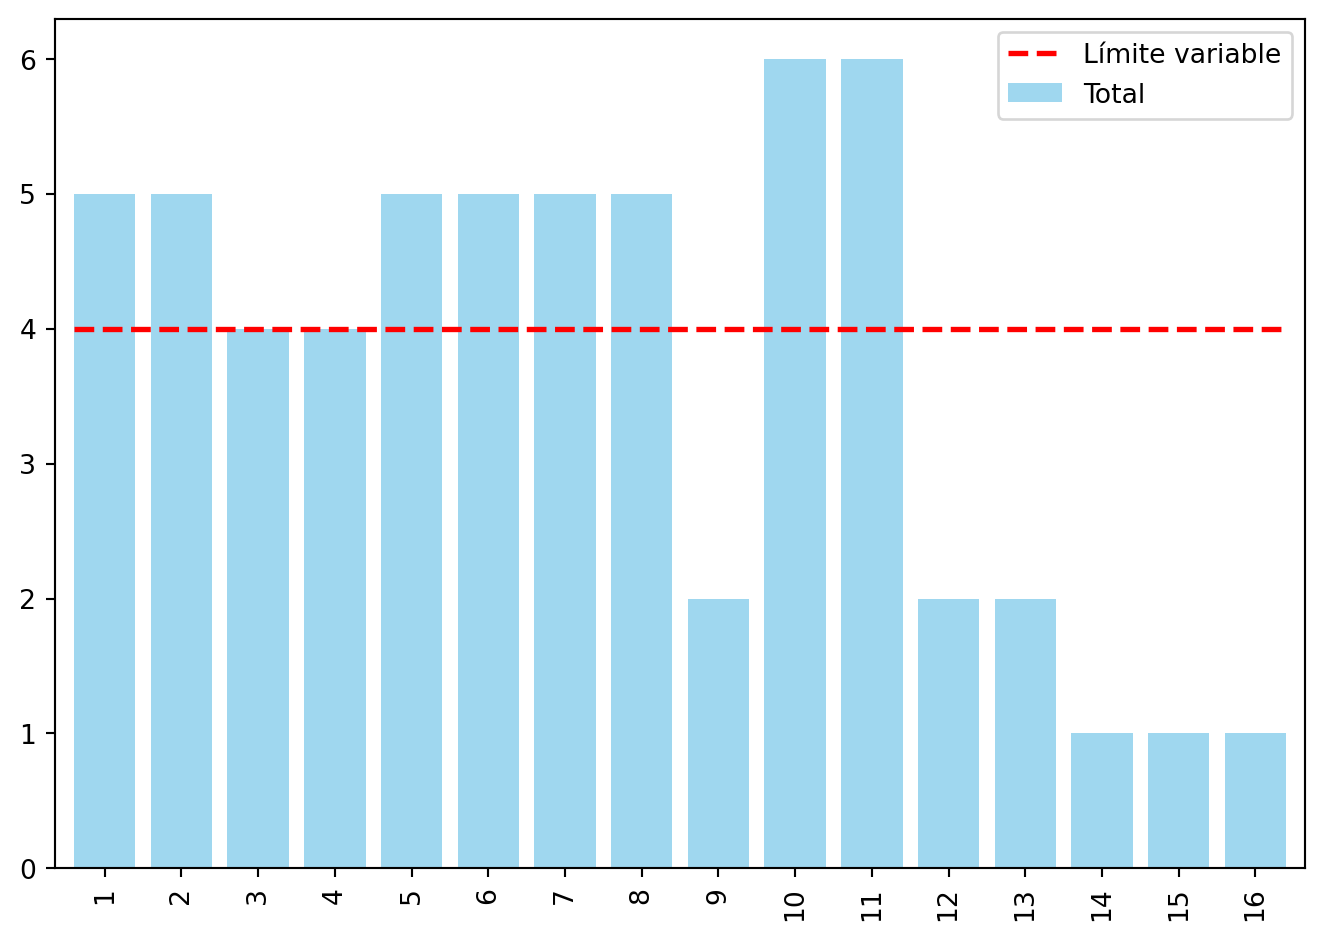

In [9]:
#| fig-cap: "Cargas con los inicios más tempranos"
#| label: fig-cargasInicial
gantt_inicial, dibujo = proyecto.copy().gantt_cargas(datos_proyecto.copy(), 'duration', 'resources', report=False, tikz=True, params=GANTT_PARAMS)
plot_cargas(gantt_df=gantt_inicial, limite_maximo_recursos=[limite])

In [10]:
cargas = gantt_inicial.data.loc['Total'].drop('H_total').astype(float)
exceso = cargas[cargas > limite]
Markdown(f'Se superan los {limite} operarios en las semanas {", ".join(str(t) for t in exceso.index)} (cargas {", ".join(f"{int(c)}" for c in exceso)}).')

Se superan los 4 operarios en las semanas 1, 2, 5, 6, 7, 8, 10, 11 (cargas 5, 5, 5, 5, 5, 5, 6, 6).

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Programe el proyecto periodo a periodo con un planificador en paralelo: en cada semana se ordenan las actividades disponibles según una regla de prioridad y se van admitiendo mientras quepan en el límite. Aplique tres reglas: (a) menor holgura total, (b) menor duración (SPT) y (c) mayor número de operarios. Dé la duración con cada una.  

El planificador recorre las semanas: una actividad es *disponible* cuando han terminado sus predecesoras; las que ya están en curso siguen (no se interrumpen) y las nuevas entran por orden de prioridad mientras quepan en el límite.

In [12]:
def planificar(datos, prelaciones, limite, prioridad, interrumpible=False, max_periodos=200):
    '''Programación en paralelo periodo a periodo con un recurso renovable limitado.
    prioridad(a, t) -> número: menor = antes. Devuelve (semanas trabajadas por actividad, inicio, fin).'''
    pred = prelaciones.immediate_predecessor
    restante = datos['duration'].astype(int).to_dict()
    rec = datos['resources'].astype(int).to_dict()
    trabajo = {a: [] for a in restante}
    en_curso = set()
    for t in range(1, max_periodos + 1):
        terminadas = {a for a, r in restante.items() if r == 0}
        if len(terminadas) == len(restante):
            break
        elegibles = [a for a in restante if restante[a] > 0 and set(pred[a]) <= terminadas]
        if not interrumpible:
            # las ya empezadas siguen; las nuevas se ordenan por prioridad
            fijas = [a for a in elegibles if a in en_curso]
            nuevas = sorted([a for a in elegibles if a not in en_curso], key=lambda a: prioridad(a, t))
            orden = fijas + nuevas
        else:
            orden = sorted(elegibles, key=lambda a: prioridad(a, t))
        disponible = limite
        activas = []
        for a in orden:
            if rec[a] <= disponible:
                activas.append(a); disponible -= rec[a]
        for a in activas:
            restante[a] -= 1; trabajo[a].append(t)
        en_curso = {a for a in activas if restante[a] > 0}
    inicio = pd.Series({a: (min(s) if s else np.nan) for a, s in trabajo.items()})
    fin = pd.Series({a: (max(s) if s else np.nan) for a, s in trabajo.items()})
    return trabajo, inicio, fin

def gantt_texto(trabajo, limite):
    '''Tabla actividad × semana con el recurso usado y fila de carga total.'''
    T = max(max(s) for s in trabajo.values() if s)
    g = pd.DataFrame('', index=list(trabajo), columns=range(1, T + 1))
    for a, semanas in trabajo.items():
        for t in semanas:
            g.loc[a, t] = int(datos_proyecto.loc[a, 'resources'])
    carga = pd.Series({t: sum(int(datos_proyecto.loc[a, 'resources']) for a, s in trabajo.items() if t in s) for t in g.columns})
    g.loc['Total'] = carga
    g.loc['≤ límite'] = ['sí' if c <= limite else 'NO' for c in carga]
    return g

In [13]:
reglas = {
    '(a) menor holgura total': lambda a, t: (calendario.loc[a, 'H_total'], a),
    '(b) menor duración (SPT)': lambda a, t: (datos_proyecto.loc[a, 'duration'], a),
    '(c) más operarios primero': lambda a, t: (-datos_proyecto.loc[a, 'resources'], a),
}
resultados = {}
for nombre, regla in reglas.items():
    trabajo, inicio, fin = planificar(datos_proyecto, prelaciones, limite, regla)
    resultados[nombre] = dict(trabajo=trabajo, inicio=inicio, fin=fin, duracion=int(fin.max()))
pd.DataFrame({nombre: r['inicio'].astype(int).rename('inicio') for nombre, r in resultados.items()}).assign(**{'sin límite': calendario['inicio_mas_temprano'] + 1}).T

,A,B,C,D,E,F,G,H,I
(a) menor holgura total,1,5,7,9,18,14,14,22,24
(b) menor duración (SPT),3,1,3,11,7,18,16,16,22
(c) más operarios primero,3,1,3,11,7,18,16,16,22
sin límite,1,1,3,5,5,10,10,10,14


In [14]:
#| tbl-cap: "Programación con la regla (a) menor holgura total"
#| label: tbl-reglaa
gantt_texto(resultados['(a) menor holgura total']['trabajo'], limite)

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26
A,1,1,1,1,,,,,,,,,,,,,,,,,,,,,,
B,,,,,4,4,,,,,,,,,,,,,,,,,,,,
C,,,,,,,3,3,,,,,,,,,,,,,,,,,,
D,,,,,,,,,2,2,2,2,2,,,,,,,,,,,,,
E,,,,,,,,,,,,,,,,,,3,3,3,3,,,,,
F,,,,,,,,,,,,,,2,2,2,2,,,,,,,,,
G,,,,,,,,,,,,,,1,1,,,,,,,,,,,
H,,,,,,,,,,,,,,,,,,,,,,3,3,,,
I,,,,,,,,,,,,,,,,,,,,,,,,1,1,1
Total,1,1,1,1,4,4,3,3,2,2,2,2,2,3,3,2,2,3,3,3,3,3,3,1,1,1


In [15]:
#| tbl-cap: "Programación con la regla (b) menor duración (SPT)"
#| label: tbl-reglab
gantt_texto(resultados['(b) menor duración (SPT)']['trabajo'], limite)

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
A,,,1,1,1,1,,,,,,,,,,,,,,,,,,
B,4,4,,,,,,,,,,,,,,,,,,,,,,
C,,,3,3,,,,,,,,,,,,,,,,,,,,
D,,,,,,,,,,,2,2,2,2,2,,,,,,,,,
E,,,,,,,3,3,3,3,,,,,,,,,,,,,,
F,,,,,,,,,,,,,,,,,,2,2,2,2,,,
G,,,,,,,,,,,,,,,,1,1,,,,,,,
H,,,,,,,,,,,,,,,,3,3,,,,,,,
I,,,,,,,,,,,,,,,,,,,,,,1,1,1
Total,4,4,4,4,1,1,3,3,3,3,2,2,2,2,2,4,4,2,2,2,2,1,1,1


In [16]:
#| tbl-cap: "Programación con la regla (c) más operarios primero"
#| label: tbl-reglac
gantt_texto(resultados['(c) más operarios primero']['trabajo'], limite)

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
A,,,1,1,1,1,,,,,,,,,,,,,,,,,,
B,4,4,,,,,,,,,,,,,,,,,,,,,,
C,,,3,3,,,,,,,,,,,,,,,,,,,,
D,,,,,,,,,,,2,2,2,2,2,,,,,,,,,
E,,,,,,,3,3,3,3,,,,,,,,,,,,,,
F,,,,,,,,,,,,,,,,,,2,2,2,2,,,
G,,,,,,,,,,,,,,,,1,1,,,,,,,
H,,,,,,,,,,,,,,,,3,3,,,,,,,
I,,,,,,,,,,,,,,,,,,,,,,1,1,1
Total,4,4,4,4,1,1,3,3,3,3,2,2,2,2,2,4,4,2,2,2,2,1,1,1


In [17]:
duraciones = pd.Series({nombre: r['duracion'] for nombre, r in resultados.items()}, name='duración (semanas)')
duraciones['sin límite de recursos'] = duracion_minima
duraciones.to_frame().T

,(a) menor holgura total,(b) menor duración (SPT),(c) más operarios primero,sin límite de recursos
duración (semanas),26,24,24,16


## Apartado 3

In [18]:
display(Markdown(pregunta_3))

3. Compare con el resultado del algoritmo de Wiest-Levy de la librería (`asignar`).  

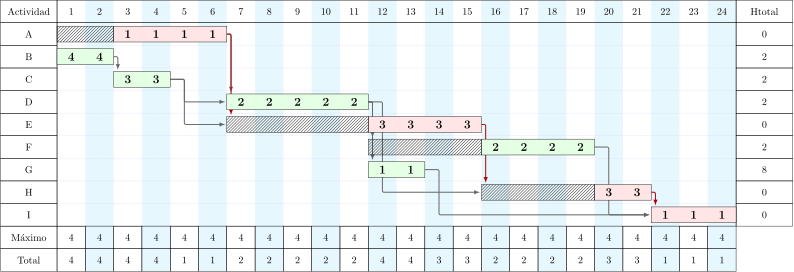

In [19]:
#| fig-cap: "Asignación de la librería (Wiest-Levy)"
#| label: fig-ganttAsignado
proyecto_asignado = proyecto.copy()
datos_asignados, gantt_asignado, dibujo = proyecto_asignado.asignar(
    data=datos_proyecto.copy(), duration_label='duration', resource_label='resources',
    maximo=[limite], report=False, params=dict(period_width=1, **GANTT_PARAMS))
pinta_tikz(dibujo)

In [20]:
duracion_libreria = len(gantt_asignado.data.columns.drop('H_total'))
Markdown(f'La librería obtiene {duracion_libreria} semanas; las reglas dan {", ".join(f"{k}: {v}" for k, v in duraciones.drop("sin límite de recursos").items())}. '
         'Wiest-Levy también es una heurística (aplaza las actividades con más holgura), de modo que ninguna de las cuatro cifras es necesariamente el óptimo.')

La librería obtiene 24 semanas; las reglas dan (a) menor holgura total: 26, (b) menor duración (SPT): 24, (c) más operarios primero: 24. Wiest-Levy también es una heurística (aplaza las actividades con más holgura), de modo que ninguna de las cuatro cifras es necesariamente el óptimo.

## Apartado 4

In [21]:
display(Markdown(pregunta_4))

4. ¿Alguna regla garantiza la duración mínima? ¿Qué información usa la regla de la holgura que no usan las otras?  

Ninguna regla garantiza el óptimo: el problema de programación con recursos limitados es NP-duro y las reglas de prioridad son heurísticas; para proyectos pequeños se puede comprobar por enumeración o programación entera. La regla de la holgura mínima es la única que usa la *estructura* del proyecto (qué actividades tienen margen y cuáles arrastrarían el plazo); SPT y «más operarios» sólo miran la actividad aislada. Por eso suele funcionar mejor, aunque no siempre: la holgura se calculó sin recursos y deja de ser exacta en cuanto se aplaza algo.